In [1]:
import numpy as np
import matplotlib.pyplot as plt
from session_data import *
from visualize import *
from antenna_array import *

%load_ext autoreload
%autoreload 2

Session: session_152325
Start: 2025-11-18 15:23:25.700764
End: 2025-11-18 15:44:15.307418
Duration: 1249.6 seconds
Total Samples: 116
Data Points: 116
Images: 116



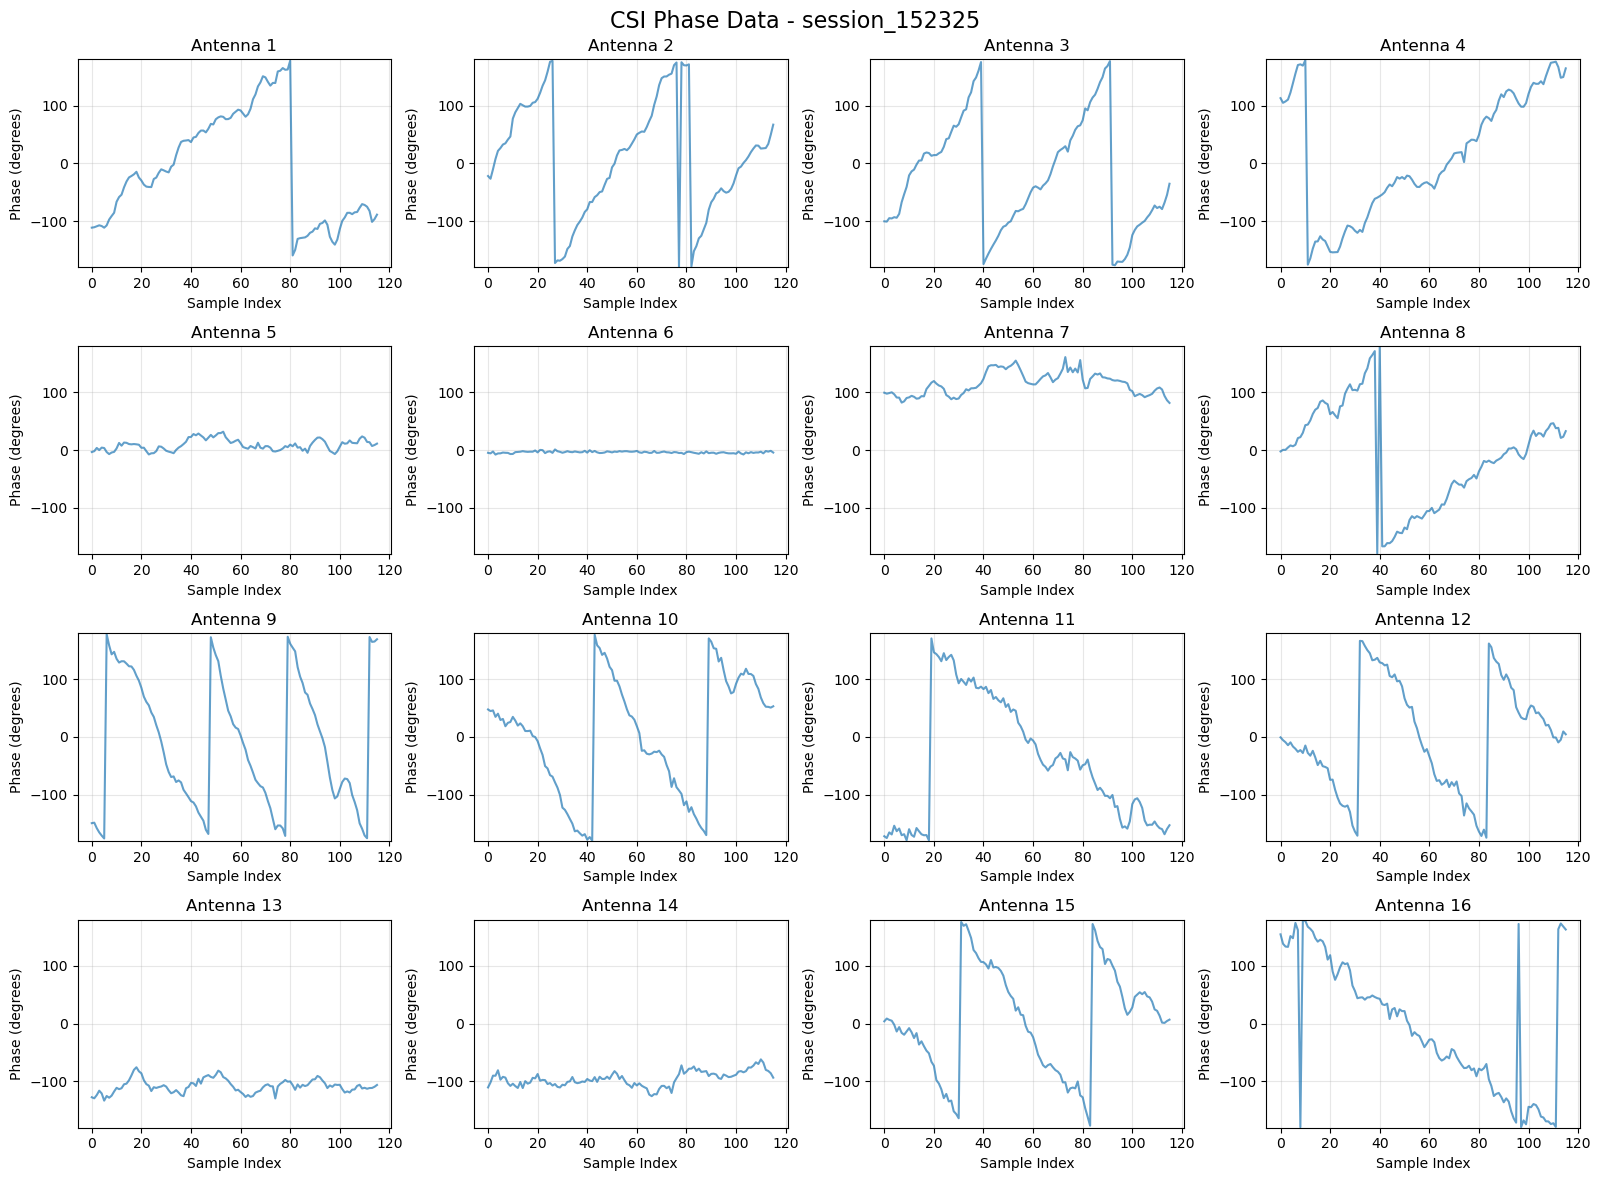

In [2]:
session_dir = Path("../data/2025-11-18/session_152325")
session = SessionData.from_directory(session_dir)
session.load_all_router_batches()
print(session.summary())

plot_csi_phase_data(session)

ValueError: too many values to unpack (expected 2)

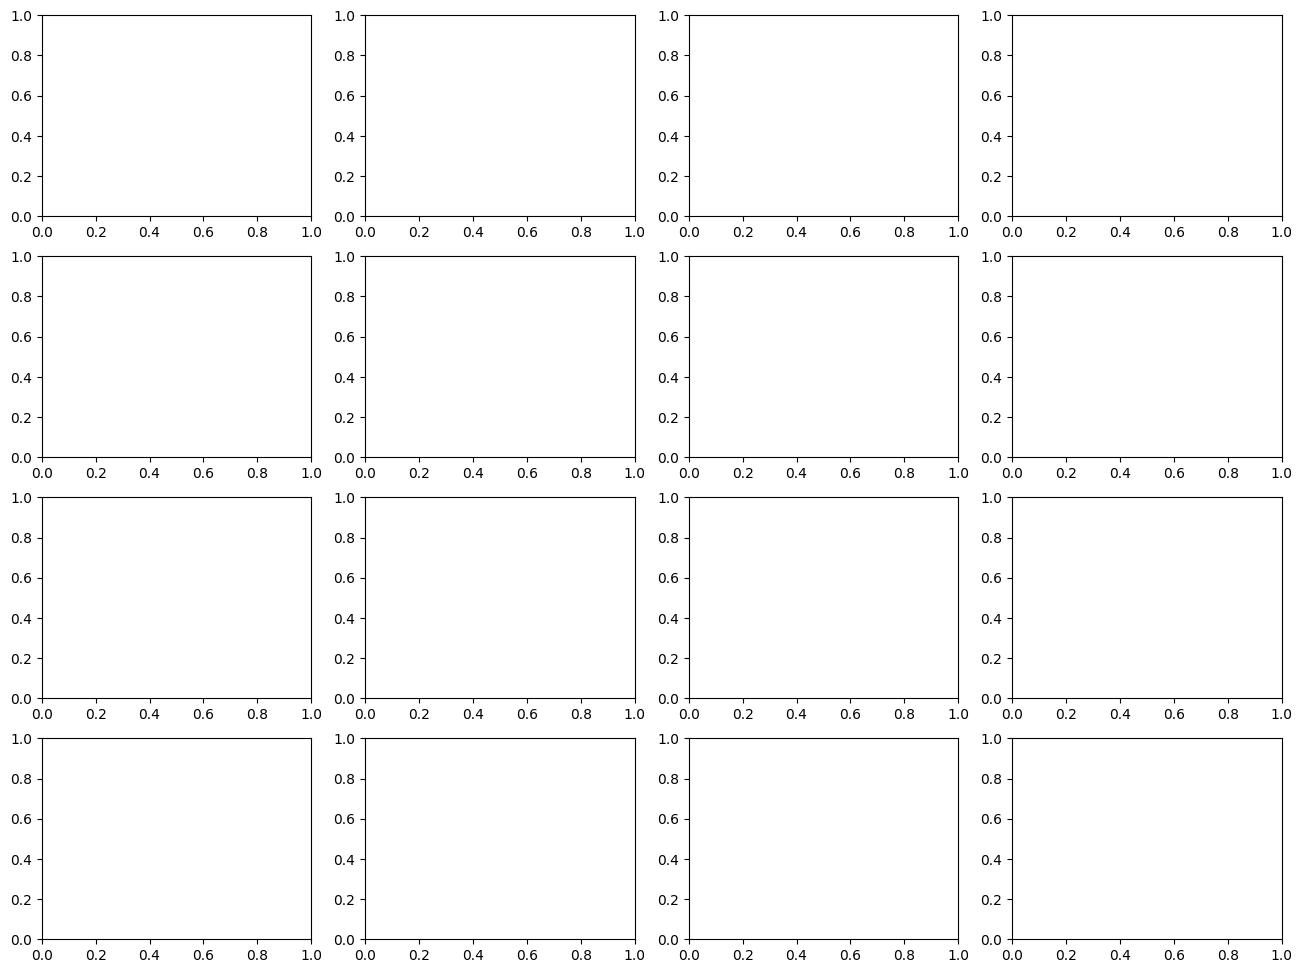

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()
channel_data, _ = read_and_process_csi_data(session)
magnitude_data = np.abs(channel_data)

# Set titles and labels for each subplot
for antenna in range(16):
    axes[antenna].plot(magnitude_data[:, antenna], markersize=3, alpha=0.7)

(116,)


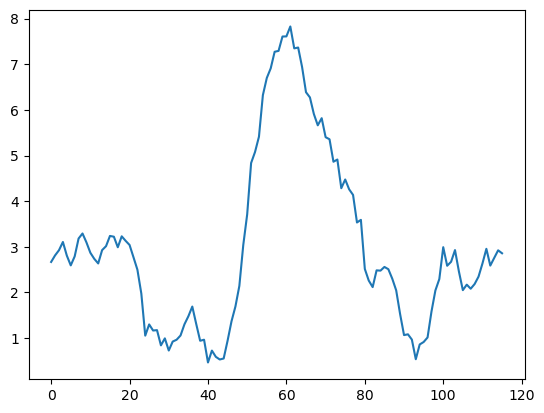

In [3]:
# channel_data = np.zeros((1, 16), dtype=np.complex128)

# for dp in session.data_points:
#     # Check if router batch is loaded
#     if dp.router_batch is None:
#         continue
        
#     csi_data = dp.router_batch.csi_processed_data
    
#     # Check if CSI data is not empty and has the right shape
#     if csi_data.size == 0 or len(csi_data.shape) < 2:
#         continue
    
#     channel_data = np.vstack((channel_data, csi_data))

channel_data = session.get_csi_data(averaged=True)

avg_channel = np.sum(channel_data, axis=1)
print(avg_channel.shape)

plt.figure()
plt.plot(np.abs(avg_channel))
plt.show()

# num_samples = channel_data.shape[0] - 1
# valid_antennas = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13, 21, 23, 25, 27]

# theta_vals = np.linspace(-80, 80, 120)
# theta_vals = np.deg2rad(theta_vals)
# num_samples = 120

# # Create antenna arrays for each sample
# spacing = 0.58 * 58.32 / 60.48
# antenna_arrays = [AntennaArray() for _ in range(num_samples)]
# antenna_arrays_real = [AntennaArray() for _ in range(num_samples)]
# for i in range(num_samples):
#     averaged_channel_data = np.mean(channel_data[i*10:(i+1)*10, :], axis=0)

#     for antenna in range(32):
#         if antenna not in valid_antennas:
#             continue
#         antenna_arrays[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
#             0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)
#         antenna_arrays_real[i].add_element(ordering_sets[antenna, 0]*spacing - np.sign(ordering_sets[antenna, 0])*spacing/2, 
#             0, ordering_sets[antenna, 1]*spacing - np.sign(ordering_sets[antenna, 1])*spacing/2)

#     w = antenna_arrays[i].get_conjugate_beamformer(az=theta_vals[i], el=np.rad2deg(30)) 
#     antenna_arrays[i].set_weights(w)
#     antenna_arrays_real[i].set_weights(np.conjugate(averaged_channel_data))

In [90]:
# Element Factor Estimation
element_factor = np.zeros((np.shape(theta_vals)[0], 16), dtype=np.complex128)

for j, theta in enumerate(theta_vals):
    element_factor[j, :] = antenna_arrays_real[j].get_array_response(theta, np.rad2deg(30)) / antenna_arrays[j].get_array_response(theta, np.rad2deg(30))

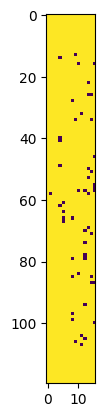

In [82]:
plt.figure()
plt.imshow(np.abs(element_factor))
plt.show()

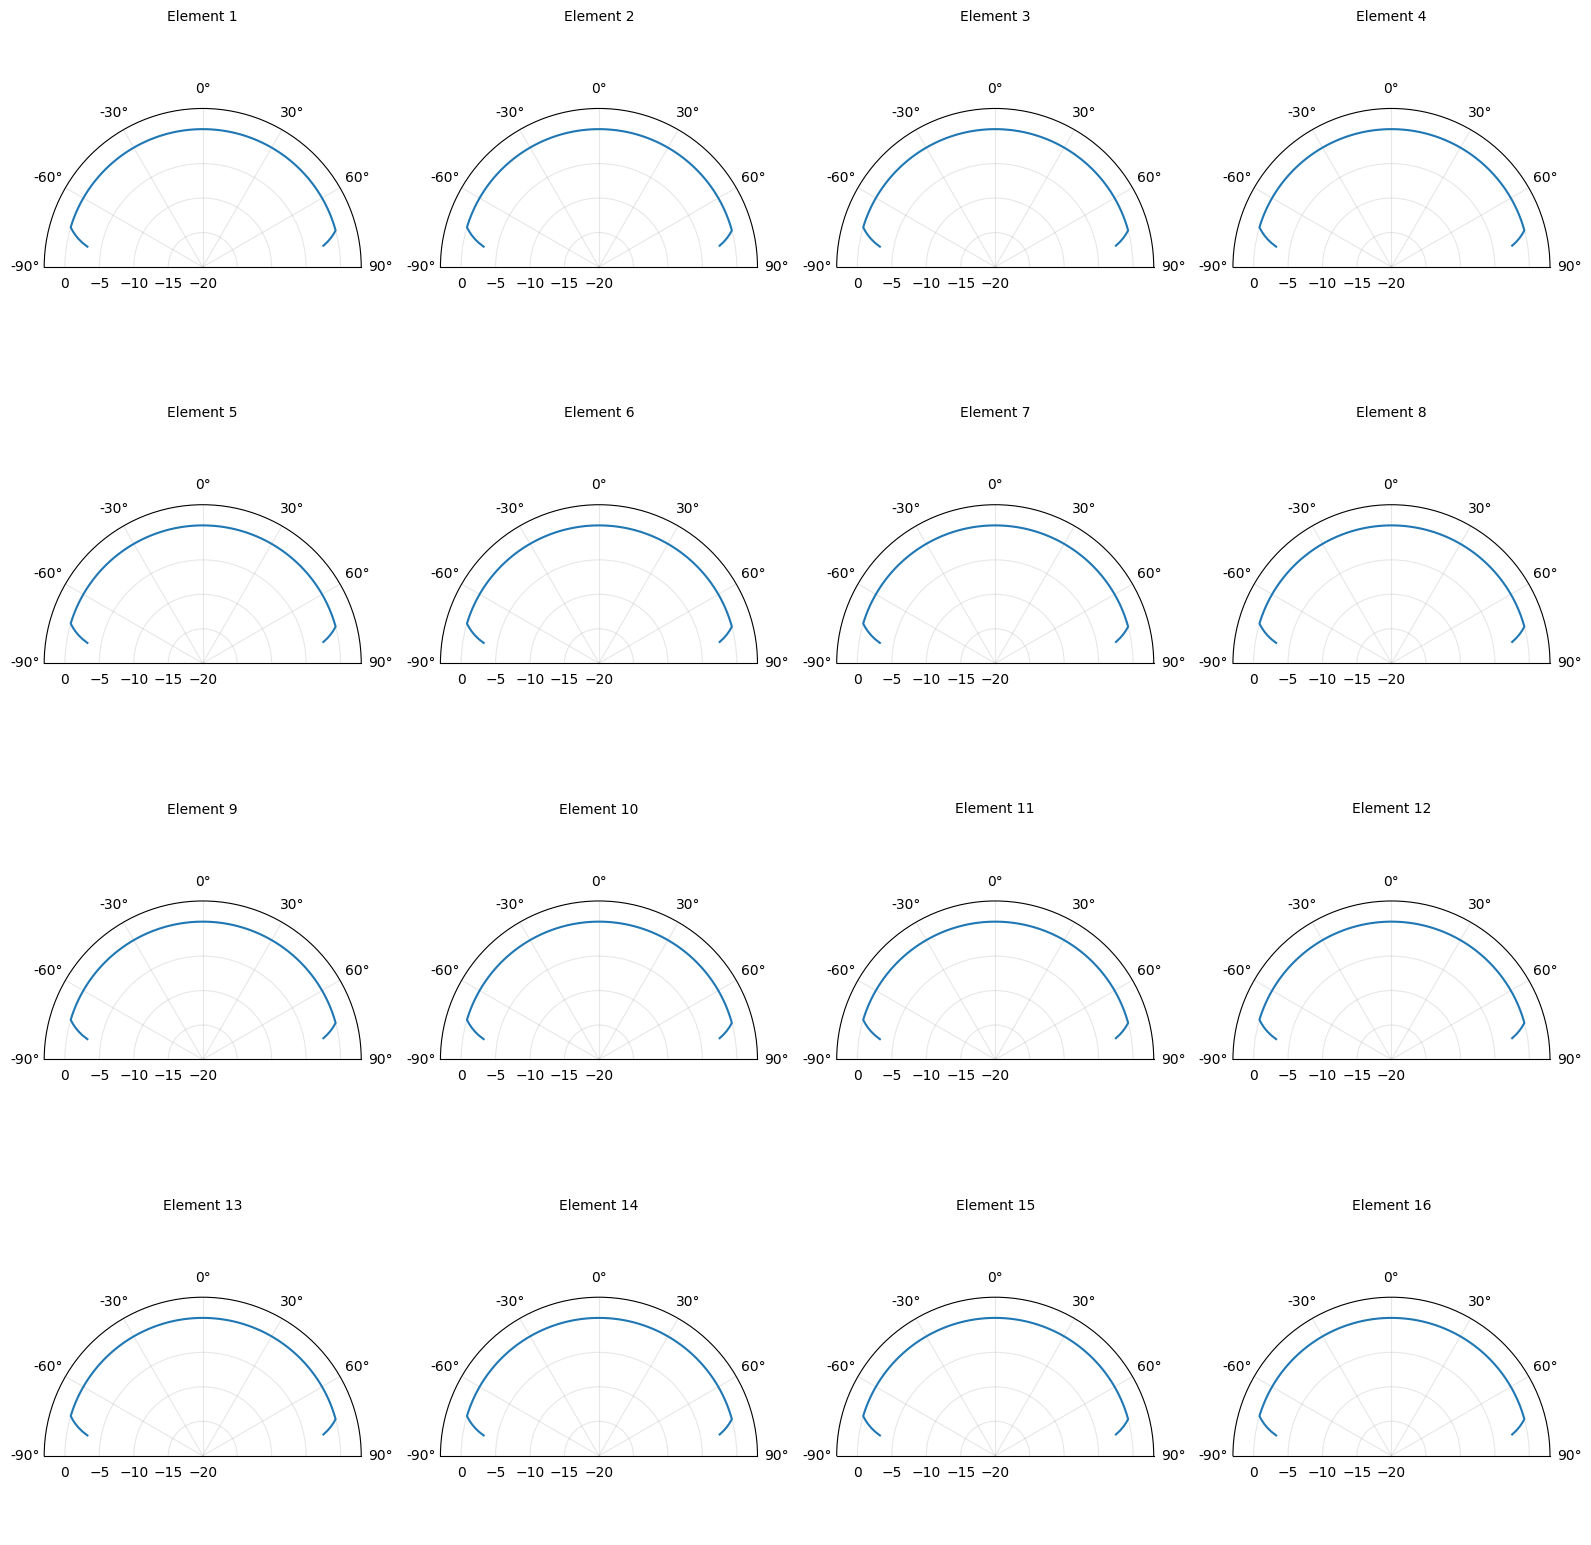

In [86]:
# Create figure with 16 subplots (4x4 grid)
fig = plt.figure(figsize=(16, 16))

# Plot first 16 elements
for idx in range(16):
    ax = plt.subplot(4, 4, idx + 1, projection='polar')
    
    element_pattern = np.abs(element_factor[:, idx])
    threshold = 1e-10 * np.max(element_pattern)
    element_pattern[element_pattern < threshold] = threshold
    element_pattern = np.convolve(element_pattern, np.ones(10)/10, mode='same')
    
    # Convert to dB with proper floor
    element_pattern_db = 10 * np.log10(element_pattern + 1e-15)
    element_pattern_db = element_pattern_db - np.max(element_pattern_db)
    
    # Optional: clip the lower bound to avoid extreme negative values
    element_pattern_db = np.maximum(element_pattern_db, -60)  # -60 dB floor
    
    # Plot
    ax.plot(theta_vals, element_pattern_db, linewidth=1.5)
    
    # Configure polar plot
    ax.set_theta_zero_location('N')  # 0° at top
    ax.set_theta_direction(-1)  # Clockwise
    ax.set_thetamin(-90)  # Set range from -90
    ax.set_thetamax(90)   # to 90 degrees
    ax.set_ylim([-20, 3])  # dB range
    ax.set_title(f'Element {idx+1}', fontsize=10)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('element_patterns_16_1.png', dpi=150, bbox_inches='tight')
plt.show()